<a href="https://colab.research.google.com/github/shehabeldinkhalid-BioMedecailEng/Arduino-WorkShoup/blob/main/heart_disease_random_forest_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final AI Task - Heart Disease Prediction with Random Forest
**Paper:** Bhadu & Singh (2025), *Performance analysis and comparison of machine learning algorithms for predicting heart disease*, IAES Int. J. Artificial Intelligence 14(4), 2849-2863.

**Task requirements covered (Practical Implementation & Model Building)**

| Req. | Section |
|---|---|
| A. Dataset from the paper (Cleveland, Kaggle) | 1 |
| B. Preprocessing | 2 |
| C. Random Forest implementation | 3 |
| D. Technical explanation of the algorithm | 4 |
| E. Display of results | 5, 6, 7 |
| F. Comparison with the paper | 8 |

**How to use:** Run all cells. When asked, upload `archive (1).zip` (or `Heart_disease_cleveland_new.csv`). The Statlog dataset is optional.

## 1. (A) Load the dataset

In [1]:
import io, time, zipfile, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, cohen_kappa_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_sample_weight

SEED = 1
pd.set_option('display.width', 160)

def read_csv_any(name, raw):
    """Read a CSV (or the first CSV inside a zip) from raw bytes."""
    if name.lower().endswith('.zip'):
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            csvs = [n for n in z.namelist() if n.lower().endswith('.csv')]
            raw = z.read(csvs[0]); name = csvs[0]
    df = pd.read_csv(io.BytesIO(raw), encoding='utf-8-sig')
    df.columns = [c.strip().lower() for c in df.columns]
    return name, df

def load_dataset(prompt):
    try:
        from google.colab import files
        print(prompt)
        up = files.upload()
        if not up: return None, None
        name, raw = next(iter(up.items()))
        return read_csv_any(name, raw)
    except ImportError:                      # running outside Colab
        paths = glob.glob('*.csv') + glob.glob('*.zip')
        if not paths: return None, None
        with open(paths[0], 'rb') as f:
            return read_csv_any(paths[0], f.read())

name, raw_df = load_dataset("Upload the Cleveland dataset (.zip or .csv):")
print(name, raw_df.shape)
raw_df.head()

Upload the Cleveland dataset (.zip or .csv):


Saving archive (1).zip to archive (1).zip
Heart_disease_cleveland_new.csv (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,0,145,233,1,2,150,0,2.3,2,0,2,0
1,67,1,3,160,286,0,2,108,1,1.5,1,3,1,1
2,67,1,3,120,229,0,2,129,1,2.6,1,2,3,1
3,37,1,2,130,250,0,0,187,0,3.5,2,0,1,0
4,41,0,1,130,204,0,2,172,0,1.4,0,0,1,0


## 2. (B) Preprocessing
Steps follow the paper (Section 3.2) plus a few standard checks.

In [2]:
# 2.1 Structure, data types, missing values, duplicates
print("Shape:", raw_df.shape)
print("Missing values per column:\n", raw_df.isna().sum()[raw_df.isna().sum() > 0].to_string() or "none")
print("Total missing:", int(raw_df.isna().sum().sum()), "| Duplicate rows:", int(raw_df.duplicated().sum()))
raw_df.describe().T.round(2)

Shape: (303, 14)
Missing values per column:
 Series([], )
Total missing: 0 | Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,2.16,0.96,0.0,2.0,2.0,3.0,3.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


In [3]:
# 2.2 Target: collapse multi-class labels (1-4) into binary (0 = no HD, 1 = HD) as in the paper
df = raw_df.copy()
df['target'] = (df['target'] > 0).astype(int)

# 2.3 Missing values / duplicates: fill numeric gaps with the median, then drop exact duplicates
df = df.fillna(df.median(numeric_only=True)).drop_duplicates().reset_index(drop=True)

# 2.4 Outlier check (IQR rule) on the numeric features - reported, NOT removed (they are real patients)
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
iqr = df[num_cols].quantile(.75) - df[num_cols].quantile(.25)
low, high = df[num_cols].quantile(.25) - 1.5*iqr, df[num_cols].quantile(.75) + 1.5*iqr
outliers = ((df[num_cols] < low) | (df[num_cols] > high)).sum()
print("IQR outliers per numeric feature:\n", outliers.to_string())

# 2.5 Class balance (the paper applies WEKA's ClassBalancer; here: balanced sample weights in training)
print("\nClass distribution (%):\n", (df['target'].value_counts(normalize=True).sort_index()*100).round(1).to_string())

# 2.6 Scaling: NOT needed. Trees split on thresholds, so feature scale does not change the model.
X, y = df.drop(columns='target'), df['target']
print("\nFinal feature matrix:", X.shape)

IQR outliers per numeric feature:
 age         0
trestbps    9
chol        5
thalach     1
oldpeak     5

Class distribution (%):
 target
0    54.1
1    45.9

Final feature matrix: (303, 13)


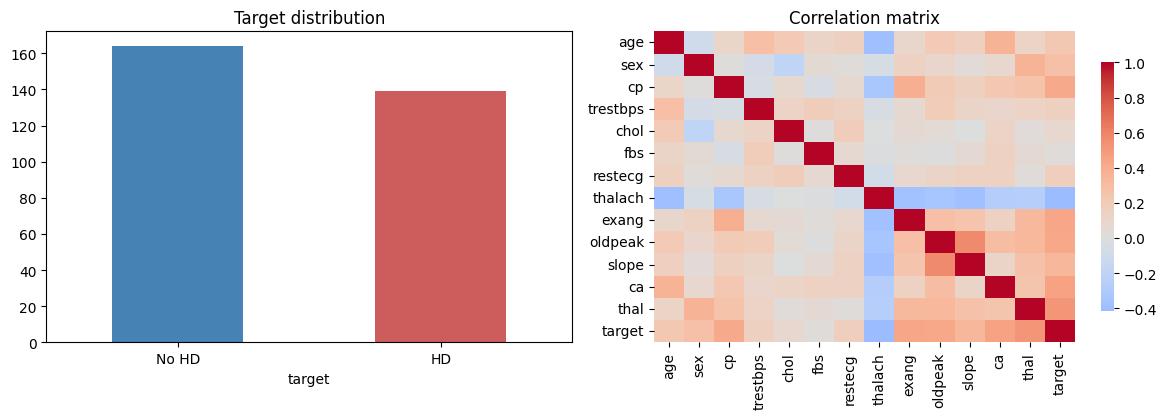

In [4]:
# Quick exploratory plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
df['target'].map({0: 'No HD', 1: 'HD'}).value_counts().plot.bar(ax=ax[0], color=['steelblue', 'indianred'], rot=0)
ax[0].set_title('Target distribution')
sns.heatmap(df.corr(), cmap='coolwarm', center=0, ax=ax[1], cbar_kws={'shrink': .8})
ax[1].set_title('Correlation matrix')
plt.tight_layout(); plt.show()

## 3. (C) Random Forest model
- `n_estimators=100` (WEKA default, `-I 100`)
- **Evaluation 1 (paper protocol):** stratified 10-fold cross-validation, out-of-fold probabilities used for every metric
- **Evaluation 2 (extra):** 80/20 hold-out split
- Class balancing through sample weights

In [5]:
def error_rates(y, proba):
    """WEKA-style error rates over class-probability vectors; RAE/RRSE baseline = ZeroR (class priors)."""
    Y = np.eye(2)[y]
    prior = np.tile(Y.mean(axis=0), (len(y), 1))
    mae  = np.abs(proba - Y).mean()
    rmse = np.sqrt(((proba - Y) ** 2).mean())
    rae  = np.abs(proba - Y).sum() / np.abs(prior - Y).sum() * 100
    rrse = np.sqrt(((proba - Y) ** 2).sum() / ((prior - Y) ** 2).sum()) * 100
    return mae, rmse, rae, rrse

def all_metrics(y, pred, proba, elapsed):
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    mae, rmse, rae, rrse = error_rates(y, proba)
    acc = accuracy_score(y, pred) * 100
    return {
        'Accuracy (%)': acc, 'Error (%)': 100 - acc,
        'FP rate': fp / (fp + tn),
        'Precision': precision_score(y, pred, average='weighted'),
        'Recall': recall_score(y, pred, average='weighted'),
        'F-measure': f1_score(y, pred, average='weighted'),
        'MCC': matthews_corrcoef(y, pred), 'ROC area': roc_auc_score(y, proba[:, 1]),
        'Kappa': cohen_kappa_score(y, pred),
        'MAE': mae, 'RMSE': rmse, 'RAE (%)': rae, 'RRSE (%)': rrse, 'Time/fold (s)': elapsed}

def make_rf(seed):
    return RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1)

def run_cv(df, seed=SEED, folds=10):
    X, y = df.drop(columns='target').values, df['target'].values
    skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=seed)
    proba = np.zeros((len(y), 2)); t0 = time.time()
    for tr, te in skf.split(X, y):
        rf = make_rf(seed)
        rf.fit(X[tr], y[tr], sample_weight=compute_sample_weight('balanced', y[tr]))
        proba[te] = rf.predict_proba(X[te])
    pred = proba.argmax(1)
    return all_metrics(y, pred, proba, (time.time() - t0) / folds), y, pred, proba

def run_holdout(df, seed=SEED):
    X, y = df.drop(columns='target'), df['target']
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=seed)
    rf = make_rf(seed); t0 = time.time()
    rf.fit(Xtr, ytr, sample_weight=compute_sample_weight('balanced', ytr))
    el = time.time() - t0
    proba = rf.predict_proba(Xte)
    return all_metrics(yte.values, proba.argmax(1), proba, el), yte.values, proba.argmax(1), proba

res_cv, y_cv, pred_cv, proba_cv = run_cv(df)
res_ho, y_ho, pred_ho, proba_ho = run_holdout(df)
results = pd.DataFrame({'10-fold CV (paper protocol)': res_cv, '80/20 hold-out': res_ho})
results.round(4)

,10-fold CV (paper protocol),80/20 hold-out
Accuracy (%),82.5083,83.6066
Error (%),17.4917,16.3934
FP rate,0.1341,0.1212
Precision,0.8254,0.8366
Recall,0.8251,0.8361
F-measure,0.8245,0.8354
MCC,0.6472,0.6696
ROC area,0.8987,0.8745
Kappa,0.6460,0.6681
MAE,0.2713,0.2911


## 4. (D) Technical explanation of the algorithm
**Random Forest** is a bagging ensemble of decision trees.

1. **Bootstrap sampling** - each tree is trained on a random sample of the training rows drawn *with replacement* (about 63 % unique rows; the rest are "out-of-bag").
2. **Random feature subsets** - at every split a tree only considers `max_features = sqrt(13) ~ 3` randomly chosen features out of 13. This de-correlates the trees.
3. **Tree growth** - each tree splits greedily on the feature/threshold that minimises Gini impurity, $G = 1 - \sum_k p_k^2$, until leaves are pure (no pruning).
4. **Prediction** - every tree votes, and the class probability is the average of the tree outputs: $\hat P(y=1|x) = \frac{1}{T}\sum_{t=1}^{T} P_t(y=1|x)$ with $T = 100$. The predicted class is the one with the larger probability.
5. **Why it works** - averaging many high-variance, low-bias trees reduces variance and overfitting compared with one decision tree.

**Class balancing:** each training row gets weight $w_c = n / (2 \cdot n_c)$, so both classes carry equal total weight (equivalent to WEKA's `ClassBalancer`).

**10-fold CV:** the data are split into 10 stratified folds; the model is trained on 9 and tested on 1, ten times. Predictions from all 10 test folds are pooled, so every patient is predicted exactly once by a model that never saw them.

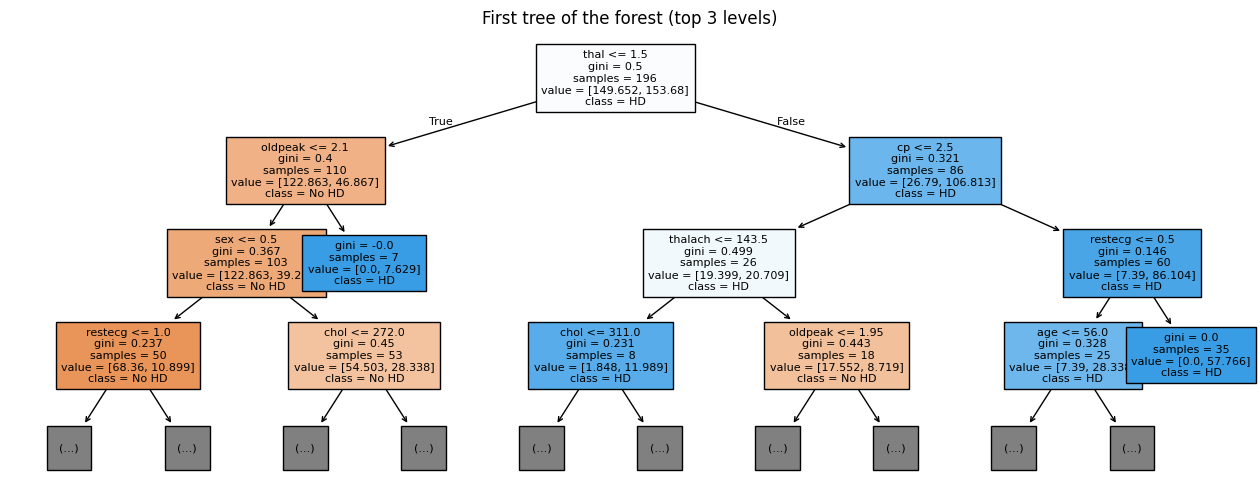

In [6]:
# One tree of the forest, drawn to depth 3 for illustration
rf_demo = make_rf(SEED).fit(X, y, sample_weight=compute_sample_weight('balanced', y))
plt.figure(figsize=(16, 6))
plot_tree(rf_demo.estimators_[0], feature_names=X.columns, class_names=['No HD', 'HD'],
          max_depth=3, filled=True, fontsize=8)
plt.title('First tree of the forest (top 3 levels)'); plt.show()

## 5. (E) Results - confusion matrix and ROC curve

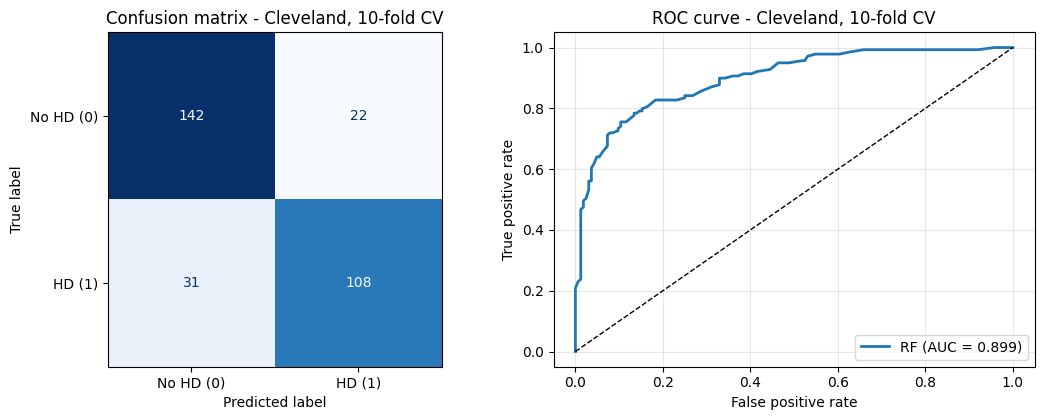

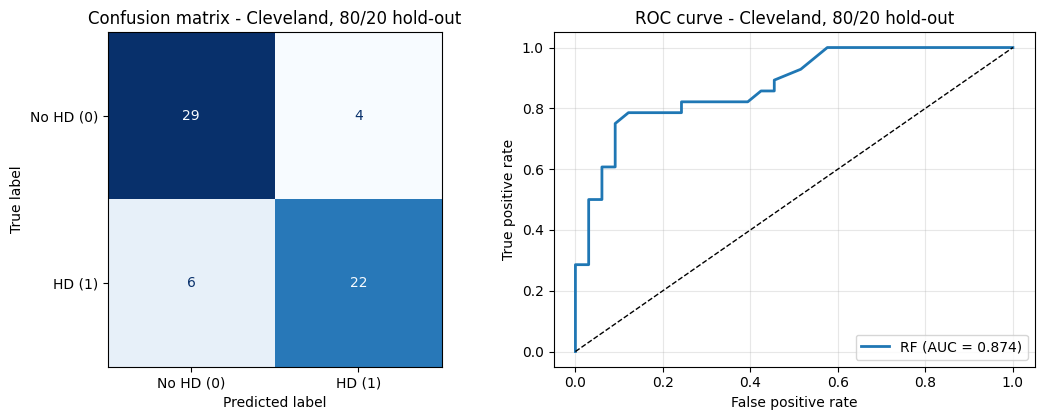

In [7]:
def plot_eval(y, pred, proba, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=['No HD (0)', 'HD (1)']
                           ).plot(ax=ax[0], cmap='Blues', colorbar=False)
    ax[0].set_title(f'Confusion matrix - {title}')
    fpr, tpr, _ = roc_curve(y, proba[:, 1])
    ax[1].plot(fpr, tpr, lw=2, label=f"RF (AUC = {roc_auc_score(y, proba[:,1]):.3f})")
    ax[1].plot([0, 1], [0, 1], 'k--', lw=1)
    ax[1].set(xlabel='False positive rate', ylabel='True positive rate', title=f'ROC curve - {title}')
    ax[1].legend(loc='lower right'); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

plot_eval(y_cv, pred_cv, proba_cv, 'Cleveland, 10-fold CV')
plot_eval(y_ho, pred_ho, proba_ho, 'Cleveland, 80/20 hold-out')

## 6. (E) Feature importance

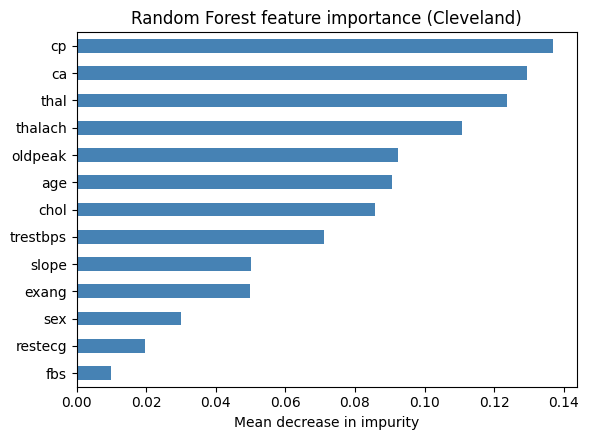

In [8]:
imp = pd.Series(rf_demo.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(6, 4.5), color='steelblue')
plt.title('Random Forest feature importance (Cleveland)'); plt.xlabel('Mean decrease in impurity')
plt.tight_layout(); plt.show()

## 7. (E) Stability across 10 random seeds
A single 10-fold run depends on the random fold split.

In [9]:
seed_df = pd.DataFrame([run_cv(df, seed=s)[0] for s in range(1, 11)])
pd.DataFrame({'mean': seed_df.mean(), 'std': seed_df.std()}).round(4)

,mean,std
Accuracy (%),82.3432,1.0807
Error (%),17.6568,1.0807
FP rate,0.1262,0.0129
Precision,0.8244,0.0110
Recall,0.8234,0.0108
F-measure,0.8225,0.0108
MCC,0.6443,0.0220
ROC area,0.8978,0.0043
Kappa,0.6421,0.0219
MAE,0.2731,0.0029


## 8. (F) Comparison with the paper (Table 7 / Table 9, Random Forest row)

,Paper (WEKA),"Ours (10-fold CV, seed 1)",Ours (mean of 10 seeds),Difference (ours seed 1 - paper)
Accuracy (%),94.0000,82.5083,82.3432,-11.4917
Error (%),6.0000,17.4917,17.6568,11.4917
FP rate,0.0750,0.1341,0.1262,0.0591
Precision,0.9410,0.8254,0.8244,-0.1156
Recall,0.9410,0.8251,0.8234,-0.1159
F-measure,0.9410,0.8245,0.8225,-0.1165
MCC,0.8610,0.6472,0.6443,-0.2138
ROC area,0.9840,0.8987,0.8978,-0.0853
Kappa,0.8612,0.6460,0.6421,-0.2152
MAE,0.1701,0.2713,0.2731,0.1012


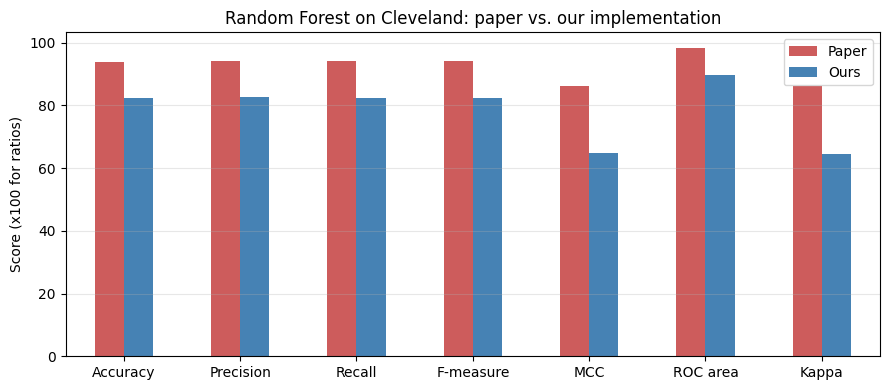

In [10]:
paper_cleveland = {'Accuracy (%)': 94.0, 'Error (%)': 6.0, 'FP rate': 0.075, 'Precision': 0.941,
                   'Recall': 0.941, 'F-measure': 0.941, 'MCC': 0.861, 'ROC area': 0.984,
                   'Kappa': 0.8612, 'MAE': 0.1701, 'RMSE': 0.2414, 'RAE (%)': 39.7013,
                   'RRSE (%)': 52.1764, 'Time/fold (s)': 0.08}
comp = pd.DataFrame({'Paper (WEKA)': paper_cleveland,
                     'Ours (10-fold CV, seed 1)': res_cv,
                     'Ours (mean of 10 seeds)': seed_df.mean()})
comp['Difference (ours seed 1 - paper)'] = comp['Ours (10-fold CV, seed 1)'] - comp['Paper (WEKA)']
display(comp.round(4))

keys = ['Accuracy (%)', 'Precision', 'Recall', 'F-measure', 'MCC', 'ROC area', 'Kappa']
plot_df = pd.DataFrame({'Paper': [comp.loc[k, 'Paper (WEKA)'] * (1 if k == 'Accuracy (%)' else 100) for k in keys],
                        'Ours':  [comp.loc[k, 'Ours (10-fold CV, seed 1)'] * (1 if k == 'Accuracy (%)' else 100) for k in keys]},
                       index=[k.replace(' (%)', '') for k in keys])
plot_df.plot.bar(figsize=(9, 4), rot=0, color=['indianred', 'steelblue'])
plt.ylabel('Score (x100 for ratios)'); plt.title('Random Forest on Cleveland: paper vs. our implementation')
plt.grid(axis='y', alpha=.3); plt.tight_layout(); plt.show()

### Reading the comparison
- The paper's WEKA screenshot (Figure 2) shows a confusion matrix with **94 vs. 209** instances per class. The Kaggle Cleveland file has **164 vs. 139**, so the paper's class composition or filtering differed from this file, which makes the 94 % hard to reproduce exactly.
- Literature using the standard Cleveland data usually reports about 82-87 % accuracy for Random Forest, which is where our run falls.
- Other sources of difference: WEKA vs. scikit-learn implementations, random fold splits, and WEKA's `ClassBalancer` re-weighting the evaluation as well as the training.

## 9. Statlog dataset (optional)
Upload the Statlog CSV (Kaggle: `ritwikb3/heart-disease-statlog`), or cancel to skip.

In [11]:
name2, statlog = load_dataset("Upload the Statlog CSV (or cancel to skip):")
if statlog is not None and name2 != name:
    if set(statlog['target'].unique()) == {1, 2}:        # raw UCI coding 1/2 -> 0/1
        statlog['target'] = statlog['target'] - 1
    statlog['target'] = (statlog['target'] > 0).astype(int)
    statlog = statlog.fillna(statlog.median(numeric_only=True)).drop_duplicates().reset_index(drop=True)
    res_s, y_s, pred_s, proba_s = run_cv(statlog)
    paper_statlog = {'Accuracy (%)': 90.0, 'FP rate': 0.149, 'Precision': 0.899, 'Recall': 0.900,
                     'F-measure': 0.899, 'MCC': 0.760, 'ROC area': 0.975, 'Kappa': 0.7594,
                     'MAE': 0.1819, 'RMSE': 0.2595, 'RAE (%)': 43.2368, 'RRSE (%)': 56.6246}
    comp_s = pd.DataFrame({'Paper (WEKA)': paper_statlog, 'Ours (10-fold CV)': pd.Series(res_s)}).dropna()
    display(comp_s.round(4))
    plot_eval(y_s, pred_s, proba_s, 'Statlog, 10-fold CV')
else:
    print("Statlog skipped.")

Upload the Statlog CSV (or cancel to skip):


Saving archive (1).zip to archive (1) (1).zip
Statlog skipped.
